# Módulo 6 — Teoría y demostraciones

Notebook de apoyo para la teoría del **Día 10** (ver [`README.md`](../README.md)),
el módulo de cierre del curso.

## Sección 1 — Determinismo: la propiedad que hace confiable un pipeline

Los mismos parámetros de entrada deben producir siempre la misma salida.
Lo verificamos ejecutando la misma función dos veces con los mismos
parámetros y comparando el resultado exactamente.

In [1]:
import sys
sys.path.insert(0, ".")
from synth_data_era5 import era5_like_dataset
import numpy as np

parametros = dict(lat_first=5, lat_last=-15, lon_first=-80, lon_last=-70,
                   nlat=10, nlon=10, start="2026-06-01", periods=24, seed=7)

ds_corrida_1 = era5_like_dataset(**parametros)
ds_corrida_2 = era5_like_dataset(**parametros)

identicos = bool(np.array_equal(ds_corrida_1["t2m"].values, ds_corrida_2["t2m"].values))
print(f"¿Dos corridas con los MISMOS parámetros dan el MISMO resultado? -> {identicos}")

parametros_seed_distinta = {**parametros, "seed": 8}
ds_corrida_3 = era5_like_dataset(**parametros_seed_distinta)
identicos_seed_distinta = bool(np.array_equal(ds_corrida_1["t2m"].values, ds_corrida_3["t2m"].values))
print(f"¿Cambiar solo la 'seed' (un parámetro) cambia el resultado? -> {not identicos_seed_distinta}")

¿Dos corridas con los MISMOS parámetros dan el MISMO resultado? -> True
¿Cambiar solo la 'seed' (un parámetro) cambia el resultado? -> True


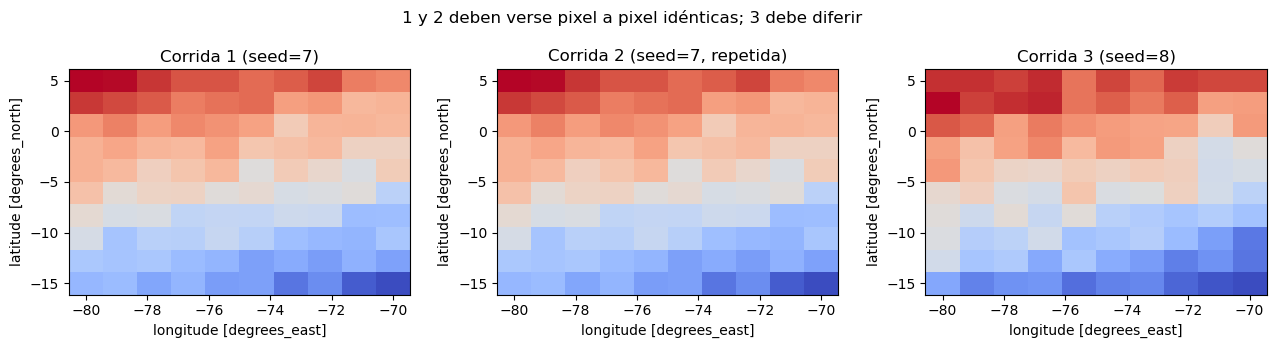

In [2]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
ds_corrida_1["t2m"].isel(time=0).plot(ax=axes[0], cmap="coolwarm", add_colorbar=False)
axes[0].set_title("Corrida 1 (seed=7)")
ds_corrida_2["t2m"].isel(time=0).plot(ax=axes[1], cmap="coolwarm", add_colorbar=False)
axes[1].set_title("Corrida 2 (seed=7, repetida)")
ds_corrida_3["t2m"].isel(time=0).plot(ax=axes[2], cmap="coolwarm", add_colorbar=False)
axes[2].set_title("Corrida 3 (seed=8)")
fig.suptitle("1 y 2 deben verse pixel a pixel idénticas; 3 debe diferir")
fig.tight_layout()
plt.show()

Esto ilustra por qué **todo** lo que afecta el resultado —incluida la
semilla aleatoria en un caso sintético, o la fecha/área/variables en un
caso real— debe ser un parámetro explícito, nunca un valor implícito
dentro del cuerpo de la función.

## Sección 2 — Separar configuración de código: el patrón de este módulo

In [3]:
def config_caso(fecha_inicio, fecha_fin, area, estacion_validacion, carpeta_base="proyecto_demo"):
    """Construye el diccionario de configuracion de un caso de estudio.
    Todo lo que cambia entre casos vive aqui, en un unico lugar."""
    return {
        "fecha_inicio": fecha_inicio,
        "fecha_fin": fecha_fin,
        "area": area,  # [norte, oeste, sur, este]
        "estacion_validacion": estacion_validacion,
        "carpeta_base": carpeta_base,
        "carpeta_entrada": f"{carpeta_base}/datos/entrada",
        "carpeta_wrfout": f"{carpeta_base}/datos/wrfout",
        "carpeta_resultados": f"{carpeta_base}/resultados",
    }

caso_demo = config_caso(
    fecha_inicio="2026-06-01", fecha_fin="2026-06-02",
    area=[5, -80, -15, -70],
    estacion_validacion={"nombre": "Demo", "lat": -9.5, "lon": -76.0},
)
caso_demo

{'fecha_inicio': '2026-06-01',
 'fecha_fin': '2026-06-02',
 'area': [5, -80, -15, -70],
 'estacion_validacion': {'nombre': 'Demo', 'lat': -9.5, 'lon': -76.0},
 'carpeta_base': 'proyecto_demo',
 'carpeta_entrada': 'proyecto_demo/datos/entrada',
 'carpeta_wrfout': 'proyecto_demo/datos/wrfout',
 'carpeta_resultados': 'proyecto_demo/resultados'}

## Sección 3 — Estructura de directorios

In [4]:
import os

def crear_estructura(config):
    carpetas = [
        config["carpeta_entrada"],
        config["carpeta_wrfout"],
        f"{config['carpeta_resultados']}/mapas",
        f"{config['carpeta_resultados']}/series",
        f"{config['carpeta_resultados']}/validacion",
        f"{config['carpeta_base']}/pipeline",
        f"{config['carpeta_base']}/notebooks",
    ]
    for carpeta in carpetas:
        os.makedirs(carpeta, exist_ok=True)
    return carpetas

carpetas_creadas = crear_estructura(caso_demo)
for c in carpetas_creadas:
    print(c)

proyecto_demo/datos/entrada
proyecto_demo/datos/wrfout
proyecto_demo/resultados/mapas
proyecto_demo/resultados/series
proyecto_demo/resultados/validacion
proyecto_demo/pipeline
proyecto_demo/notebooks


## Sección 4 — Entorno fijado: exportar las versiones exactas de las librerías

Esto sí se ejecuta contra el entorno real de este curso (no es simulado):

In [5]:
import subprocess

resultado = subprocess.run(
    ["pip", "list", "--format=freeze"],
    capture_output=True, text=True,
)
paquetes_clave = [
    l for l in resultado.stdout.splitlines()
    if l.split("==")[0].lower() in {
        "numpy", "pandas", "xarray", "matplotlib", "cartopy", "cfgrib",
        "xwrf", "herbie-data", "cdsapi", "scipy", "netcdf4",
    }
]
with open(f"{caso_demo['carpeta_base']}/entorno.txt", "w") as f:
    f.write("\n".join(paquetes_clave) + "\n")

print("\n".join(paquetes_clave))
print()
print(f"Guardado en {caso_demo['carpeta_base']}/entorno.txt")

Cartopy==0.25.0
cdsapi==0.7.7
cfgrib==0.9.15.1
herbie-data==2026.3.0
matplotlib==3.10.8
netCDF4==1.7.4
numpy==2.4.2
pandas==3.0.0
scipy==1.16.0
xarray==2026.1.0
xwrf==0.0.5

Guardado en proyecto_demo/entorno.txt


---
Continuar con
[`02_practica_montaje_pipeline.ipynb`](02_practica_montaje_pipeline.ipynb).